# Lição 5 · A planilha e o painel

pandas: contar, filtrar e conferir a pauta sem abrir o Excel. É o **Piso** do curso: um painel que funciona.

**Cenário fictício.** Na Comarca de Guaraí, a **Dalva** é assessora do cartório que atende as três varas. Toda semana ela prepara os despachos padrão da pauta. A comarca descrita, as pessoas e os processos são inventados para o curso; os números de processo têm dígito verificador propositalmente inválido. No Tocantins todo processo é digital e tramita no eproc.

**Como usar:** execute as células de cima para baixo (▶ ou Ctrl+Enter). O Colab amanhece limpo: ao reabrir, use *Ambiente de execução → Executar tudo*. As células marcadas **Sua vez** são para você escrever; a célula **Conferir** logo abaixo diz se está certo.

**Arquivos:** `pauta.xlsx` tem os 12 processos da pauta; `processos.xlsx` é a base de 36. O caderno chama de
`processos.xlsx` a planilha de 12; aqui ela é `pauta.xlsx`. No código, `df` é sempre a pauta e `base` é a base.
A primeira célula baixa os arquivos; não é preciso fazer upload.

In [1]:
# Baixa as planilhas do material de apoio, só se ainda não estiverem nesta pasta.
import os
import urllib.request

BASE = "https://raw.githubusercontent.com/rogernogueira/curso_python/main/"
for caminho in [
    "dados/pauta.xlsx",
    "dados/processos.xlsx",
    "dados/audiencias.xlsx",
]:
    nome = os.path.basename(caminho)
    if os.path.exists(nome):
        print("já está aqui:", nome)
    else:
        urllib.request.urlretrieve(BASE + caminho, nome)
        print("baixado:", nome)

já está aqui: pauta.xlsx
já está aqui: processos.xlsx
já está aqui: audiencias.xlsx


## 1. Biblioteca e DataFrame

Uma **biblioteca** é um conjunto de ferramentas prontas; o pandas é o receituário das planilhas e já vem instalado no Colab.
`pd.read_excel` lê a planilha num **DataFrame** (a tabela do pandas). O `head()` é o cinto de segurança: espiar antes de calcular.

In [2]:
import pandas as pd

df = pd.read_excel("pauta.xlsx")
print(df.head())

             numero_processo            nome_parte             vara  \
0  0004512-33.2026.8.27.0001  Ana Ribeiro Nogueira    1ª Vara Cível   
1  0003745-25.2025.8.27.0001   Bruno Cardoso Teles    2ª Vara Cível   
2  0001404-60.2024.8.27.0001   Carla Duarte Macedo  Vara de Família   
3  0003953-43.2024.8.27.0001  Diego Fontes Lacerda    1ª Vara Cível   
4  0004082-48.2024.8.27.0001  Elisa Barros Pacheco    2ª Vara Cível   

          status  valor_causa data_prazo  
0       concluso        15400 2026-09-28  
1  prazo vencido        82350 2026-09-09  
2     aguardando         4980 2026-10-06  
3  prazo vencido       120000 2026-08-25  
4       concluso        27500 2026-09-22  


Com `print`, a tabela sai em texto; se não couber na largura, o pandas a quebra em blocos, e a barra `\` no fim da linha avisa
que as colunas continuam embaixo. Sem `print`, `df.head()` sozinho na última linha vira uma tabela desenhada pelo Colab.

In [3]:
print(df.columns)

Index(['numero_processo', 'nome_parte', 'vara', 'status', 'valor_causa',
       'data_prazo'],
      dtype='object')


Uma linha da planilha vira a ficha da lição 3, com dois campos a mais. A data chega como data do pandas (Timestamp).

In [4]:
processo = df.iloc[0].to_dict()
print(processo["nome_parte"], "—", processo["status"])

Ana Ribeiro Nogueira — concluso


## 2. A tabela dinâmica de uma linha

`value_counts()` conta quantas vezes cada valor aparece. Na saída, a primeira linha repete o nome da coluna; na última,
`count` é o nome da contagem e `int64`, o tipo dos números.

In [5]:
print(df["vara"].value_counts())

vara
1ª Vara Cível      5
2ª Vara Cível      4
Vara de Família    3
Name: count, dtype: int64


Outras receitas de coluna: soma, média e máximo. O total sai `833910` (sem `.0`, como no caderno) porque a planilha só tem valores inteiros.

In [6]:
print("Valor total: R$", df["valor_causa"].sum())

Valor total: R$ 833910


In [7]:
print("Valor médio: R$", df["valor_causa"].mean())

Valor médio: R$ 69492.5


In [8]:
print("Maior valor: R$", df["valor_causa"].max())

Maior valor: R$ 310000


## 3. A peneira: o filtro

`df[df["coluna"] <operador> valor]` deixa só as linhas em que a comparação é verdadeira; `len()` conta as linhas.

**Data de referência fixa.** O caderno usa `pd.Timestamp.today()`, e a resposta muda com o calendário; além disso, `today()` traz a hora,
e um prazo que vence hoje já passa por `<`. O curso fixa `hoje = pd.Timestamp("2026-09-15")`.

In [9]:
hoje = pd.Timestamp("2026-09-15")
vencidos = df[df["data_prazo"] < hoje]
print("Processos vencidos:", len(vencidos))

Processos vencidos: 5


Pelo status, a conta é outra: o status é o que o cartório registrou; a data é o fato.

In [10]:
por_status = df[df["status"] == "prazo vencido"]
print("Pelo status:", len(por_status))

Pelo status: 3


In [11]:
hoje = pd.Timestamp("2026-09-15")
aguardando = df[df["status"] == "aguardando"]
atrasados = aguardando[aguardando["data_prazo"] < hoje]
print(atrasados["nome_parte"].tolist())

['Fábio Almeida Jardim', 'Jonas Guimarães Uchoa']


O filtro com grafia errada não dá erro: devolve zero linhas, calado. Conferir o `len()` é o hábito que denuncia.

In [12]:
segunda = df[df["vara"] == "2a Vara Civel"]
print(len(segunda))

0


## 4. O socorro do KeyError

A coluna se chama `vara`, minúscula. Pedir `Vara` dá **KeyError** (erro de chave). O socorro: `print(df.columns)`, comparar letra por letra e corrigir. Descomente a célula abaixo (apague os `# `) e execute. A última linha do erro, executada de verdade, é:

```
KeyError: 'Vara'
```
 No Colab o cabeçalho do traceback tem outro formato; a **última linha** é a mesma.

In [13]:
# Erro de propósito: descomente para ver o erro, depois comente de novo.
# import pandas as pd
# df = pd.read_excel("pauta.xlsx")
# print(df["Vara"].value_counts())

## 5. O gráfico

O `;` no fim só esconde uma linha técnica (`<Axes: …>`) que o Colab mostraria acima do gráfico.

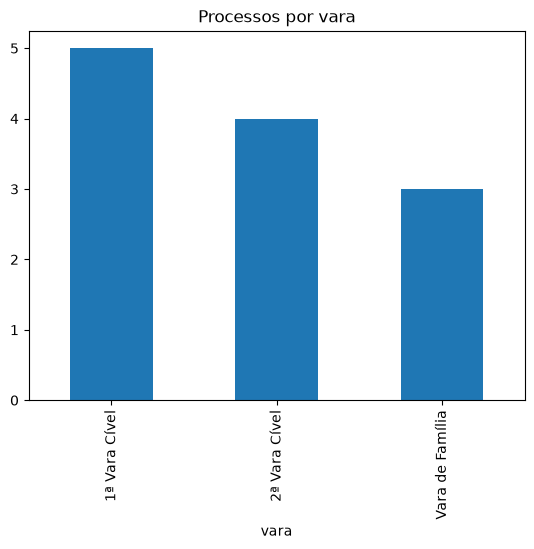

In [14]:
df["vara"].value_counts().plot(kind="bar", title="Processos por vara");

### Sua vez: o painel da base

Com a base de 36 processos, responda às três perguntas usando a peneira e o `len()`.

In [15]:
base = pd.read_excel("processos.xlsx")
hoje = pd.Timestamp("2026-09-15")

# Sua vez: escreva aqui
aguardando = ...      # quantos processos da base estão com status "aguardando"?
vencidos_base = ...   # quantos têm prazo vencido em 15/09/2026?
abaixo_50 = ...       # quantos têm valor da causa abaixo de 50000?

In [16]:
# Conferir (não precisa editar)
respostas = {"aguardando": 10, "vencidos_base": 12, "abaixo_50": 15}
for nome, certo in respostas.items():
    valor = globals().get(nome, ...)
    if valor is ...:
        print(f"✕ {nome}: escreva o filtro e o len().")
    elif valor == certo:
        print(f"✓ {nome} = {certo}")
    else:
        print(f"✕ {nome} = {valor!r}. Monte a peneira base[base[\"coluna\"] <operador> valor] e conte com len().")

✕ aguardando: escreva o filtro e o len().
✕ vencidos_base: escreva o filtro e o len().
✕ abaixo_50: escreva o filtro e o len().


### Sua vez: as audiências não realizadas

Na agenda do fórum (`audiencias.xlsx`), quantas audiências **não** foram realizadas, e qual sala deixou de realizar mais?

In [17]:
import pandas as pd
aud = pd.read_excel("audiencias.xlsx")
print(aud["sala"].value_counts())

sala
Sala 1    11
Sala 2    11
Sala 3    10
Name: count, dtype: int64


In [18]:
aud = pd.read_excel("audiencias.xlsx")

# Sua vez: escreva aqui
nao = ...           # a peneira das não realizadas
total_nao = ...     # quantas são
sala_mais = ...     # o nome da sala com mais não realizadas, por exemplo "Sala 1"

In [19]:
# Conferir (não precisa editar)
if total_nao is ... or sala_mais is ...:
    print("✕ Escreva a peneira, a contagem e a sala.")
else:
    print("✓ total = 11" if total_nao == 11 else f"✕ total = {total_nao!r}: use len(nao), com nao = aud[aud[\"realizada\"] == \"não\"].")
    print("✓ sala = Sala 2" if sala_mais == "Sala 2" else f"✕ sala = {sala_mais!r}: conte com nao[\"sala\"].value_counts(); a primeira linha é a maior.")

✕ Escreva a peneira, a contagem e a sala.


## Para conferir com a lição

- Espie com `head()` antes de calcular; em KeyError, `print(df.columns)`.
- Filtro vazio não avisa: confira o `len()`.
- O painel descreve, não decide; e a média é puxada por valores fora da curva.

**Na lição 6:** as peças se juntam e o gerador escreve um documento do Word por processo.